# RCAEval: Reduksi Kolom Metrik dengan PCA (2 PC) dan Visualisasinya

Dataset: [`phamquiluan/RCAEval`](https://huggingface.co/datasets/phamquiluan/RCAEval),
ground truth: kolom `root_cause_service`.

Setiap case punya puluhan sampai ratusan kolom metrik (mis. 49 s.d. 59 di RE1-OB). Notebook ini
mereduksi **kolom metrik menjadi 2 principal component (PC1, PC2)** dengan PCA, lalu menampilkan:

1. **Variance explained**: seberapa banyak informasi yang dipertahankan 2 PC.
2. **Deret waktu PC1/PC2** untuk satu contoh case per service (garis putus-putus = `inject_time`).
3. **Scatter titik waktu** di ruang PC1-PC2: normal vs faulty, dan faulty diwarnai per `root_cause_service`.
4. **Scatter level case**: tiap case satu titik (rata-rata PC periode faulty dikurangi periode normal), diwarnai per service.

Alur preprocessing sama dengan notebook SSL sebelumnya: kolom disatukan (union), z-score memakai statistik
**periode normal** per case, `inject_time` rusak diperbaiki, kolom `time` ganda dibuang.
Dua PC hampir pasti membuang sebagian informasi; panel variance explained dan skor silhouette
membantu menilai seberapa jauh.

## 1. Setup

In [ ]:
# Jalankan sekali (Colab/Kaggle). Lewati bila environment sudah siap.
!pip -q install pandas pyarrow huggingface_hub scikit-learn matplotlib tqdm

In [1]:
import os, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
warnings.filterwarnings("ignore")

try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x

CFG = dict(
    DATASET       = "RE1-OB",   # RE1-OB/SS/TT, RE2-OB/SS/TT, RE3-OB/SS/TT
    DRY_RUN       = False,      # True = data sintetis (tanpa internet) untuk uji notebook
    N_COMPONENTS  = 2,
    FIT_ON        = "all",      # "all" = PCA dari periode normal+faulty | "normal" = hanya periode normal
    MAX_FIT_ROWS  = 200_000,    # batas baris (timestep) untuk fitting PCA
    EXAMPLE_FAULT = "cpu",      # jenis fault untuk plot deret waktu (dipilih otomatis bila tidak ada)
    CLIP          = 10.0,       # clip z-score
    OUT_DIR       = "pca_outputs",
    DATA_DIR      = "rcaeval_data",
    HF_REPO       = "phamquiluan/RCAEval",
)
os.makedirs(CFG["OUT_DIR"], exist_ok=True)

## 2. Load dan preprocessing data

- Nama service spesifik per sistem, jadi satu dataset (mis. `RE1-OB`) dipakai per run.
- Jumlah metrik berbeda antar case -> kolom disatukan (union); kolom yang hilang diisi 0 setelah z-score.
- `inject_time` rusak (mis. `re1ob_currencyservice_loss_1` = 16.933.142) -> diganti titik tengah seri.

In [2]:
def prefix_of(dataset):          # "RE1-OB" -> "re1ob"
    return dataset.replace("-", "").lower()

def fix_inject(inject, t0, t1, n):
    if inject is None or not (t0 < inject < t1):
        return int(t0 + (n - 1) // 2)
    return int(inject)

def preprocess_case(df, inject_time, all_cols):
    df = df.sort_values("time").reset_index(drop=True)
    t = df["time"].to_numpy(dtype=np.int64)
    X = (df.drop(columns=["time"]).astype(np.float64)
           .replace([np.inf, -np.inf], np.nan).ffill().bfill())
    inject_time = fix_inject(inject_time, t[0], t[-1], len(t))
    inj = int(np.clip(np.searchsorted(t, inject_time), 8, len(t) - 8))
    ref = X.iloc[:inj]                                  # periode normal
    sd = ref.std()
    sd = sd.where(sd > 1e-8, X.std())
    sd = sd.where(sd > 1e-8, 1.0)
    Z = ((X - ref.mean()) / sd).clip(-CFG["CLIP"], CFG["CLIP"])
    Z = Z.reindex(columns=all_cols).fillna(0.0)
    return Z.to_numpy(np.float32), inj

def load_index():
    from huggingface_hub import hf_hub_download
    p = hf_hub_download(CFG["HF_REPO"], "cases.parquet", repo_type="dataset")
    return pd.read_parquet(p)

def download_cases(prefix):
    from huggingface_hub import snapshot_download
    return snapshot_download(
        repo_id=CFG["HF_REPO"], repo_type="dataset", local_dir=CFG["DATA_DIR"],
        allow_patterns=[f"{prefix}*/metrics.parquet", f"{prefix}*/inject_time.txt"])

def read_case(case_dir, inject_fallback):
    df = pd.read_parquet(case_dir / "metrics.parquet")
    df = df.loc[:, ~df.columns.duplicated()]            # kolom 'time' ganda di sebagian RE1-OB
    f, inj = case_dir / "inject_time.txt", inject_fallback
    if f.exists():
        try:
            inj = int(float(f.read_text().strip()))
        except Exception:
            pass
    return df, inj

def schema_cols(case_dir):
    import pyarrow.parquet as pq
    names = pq.read_schema(case_dir / "metrics.parquet").names
    return [c for c in dict.fromkeys(names) if c != "time"]

def make_synthetic(n_svc=5, faults=("cpu", "mem", "delay", "loss"), reps=5, ch=6, T=721, seed=0):
    rng = np.random.default_rng(seed)
    svcs = [f"svc{i}" for i in range(n_svc)]
    cols = [f"{s}_m{j}" for s in svcs for j in range(ch)]
    rows, raw, t0, k = [], {}, 1_690_000_000, 0
    for si, s in enumerate(svcs):
        for fi, f in enumerate(faults):
            for r in range(1, reps + 1):
                case = f"syn_{s}_{f}_{r}"
                X = rng.normal(0, 1, (T, len(cols))).cumsum(0) * 0.05 + rng.normal(0, 1, (T, len(cols)))
                X = X * rng.uniform(0.5, 5, len(cols)) + rng.uniform(0, 100, len(cols))
                inj = T // 2
                sl = slice(si * ch, (si + 1) * ch)
                wave = np.sin(np.linspace(0, 6 * (fi + 1), T - inj))[:, None]
                X[inj:, sl] += (2 + fi) * wave * rng.uniform(0.5, 1.5, ch) * X[:inj, sl].std(0)
                df = pd.DataFrame(X, columns=cols)
                df.insert(0, "time", t0 + np.arange(T))
                if f == "delay":
                    df = df.drop(columns=[cols[-1]])
                inj_t = t0 + inj if k > 0 else 12345
                raw[case] = (df, inj_t); k += 1
                rows.append(dict(case=case, dataset="SYN", root_cause_service=s, fault=f,
                                 repetition=r, inject_time=inj_t))
    return pd.DataFrame(rows), raw

def load_all():
    if CFG["DRY_RUN"]:
        idx, raw = make_synthetic()
        get = lambda c: raw[c]
        cols_of = lambda c: [x for x in raw[c][0].columns if x != "time"]
    else:
        idx = load_index()
        idx = idx[idx.dataset == CFG["DATASET"]].reset_index(drop=True)
        assert len(idx) > 0, f"dataset {CFG['DATASET']} tidak ditemukan di cases.parquet"
        root = download_cases(prefix_of(CFG["DATASET"]))
        inj_map = dict(zip(idx.case, idx.inject_time))
        get = lambda c: read_case(Path(root) / c, inj_map[c])
        cols_of = lambda c: schema_cols(Path(root) / c)
    all_cols = sorted({c for case in idx.case for c in cols_of(case)})
    Zs, injs = [], []
    for case in tqdm(list(idx.case), desc="preprocess"):
        df, inj_t = get(case)
        Z, inj = preprocess_case(df, inj_t, all_cols)
        Zs.append(Z); injs.append(inj)
    y = idx.root_cause_service.to_numpy().astype(str)
    return dict(idx=idx, Z=Zs, inj=np.array(injs), cols=all_cols, y=y,
                classes=sorted(set(y)), fault=idx.fault.to_numpy().astype(str),
                rep=idx.repetition.to_numpy().astype(int))

DATA = load_all()
n, C = len(DATA["Z"]), len(DATA["cols"])
name = "SINTETIS" if CFG["DRY_RUN"] else CFG["DATASET"]
print(f"{name}: {n} case | {C} kolom metrik (union) | {len(DATA['classes'])} service")
pd.crosstab(DATA["y"], DATA["fault"])

preprocess: 100%|██████████| 125/125 [00:08<00:00, 15.10it/s]


RE1-OB: 125 case | 95 kolom metrik (union) | 5 service


col_0,cpu,delay,disk,loss,mem
row_0,,,,,
adservice,5,5,5,5,5
cartservice,5,5,5,5,5
checkoutservice,5,5,5,5,5
currencyservice,5,5,5,5,5
productcatalogservice,5,5,5,5,5


## 3. PCA: kolom metrik -> 2 PC

Baris = timestep (digabung dari semua case), kolom = metrik (sudah di-z-score per case).
PCA di-fit **sekali** pada sampel baris dari semua case, sehingga PC1/PC2 punya arti yang sama di semua case
dan bisa dibandingkan. Tanda (+/-) sebuah PC bersifat sembarang, tetapi konsisten antar case.

In [3]:
rng = np.random.default_rng(0)
per_case = max(50, CFG["MAX_FIT_ROWS"] // n)
parts = []
for i in range(n):
    Z, inj = DATA["Z"][i], DATA["inj"][i]
    seg = Z if CFG["FIT_ON"] == "all" else Z[:inj]
    sel = rng.choice(len(seg), min(per_case, len(seg)), replace=False)
    parts.append(seg[sel])
X_fit = np.concatenate(parts)
print("data fit PCA:", X_fit.shape, f"(FIT_ON={CFG['FIT_ON']})")

pca = PCA(n_components=CFG["N_COMPONENTS"], random_state=0).fit(X_fit)
pca_full = PCA(n_components=min(10, C, len(X_fit)), random_state=0).fit(X_fit)     # hanya untuk grafik variance

P = [pca.transform(Z) for Z in DATA["Z"]]                  # tiap elemen: (T, 2)
print("variance explained  PC1 = %.1f%% | PC2 = %.1f%% | total 2 PC = %.1f%%" % (
    100 * pca.explained_variance_ratio_[0], 100 * pca.explained_variance_ratio_[1],
    100 * pca.explained_variance_ratio_.sum()))

# palet warna per service & marker per jenis fault
classes, faults = DATA["classes"], sorted(set(DATA["fault"]))
cmap = plt.get_cmap("tab10")
COLOR = {s: cmap(i % 10) for i, s in enumerate(classes)}
MARK = {f: m for f, m in zip(faults, ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h"])}
def savefig(fig, name):
    fig.savefig(os.path.join(CFG["OUT_DIR"], name), dpi=150, bbox_inches="tight")

data fit PCA: (132538, 95) (FIT_ON=all)
variance explained  PC1 = 19.8% | PC2 = 17.1% | total 2 PC = 36.9%


## 4. Grafik 1: variance explained

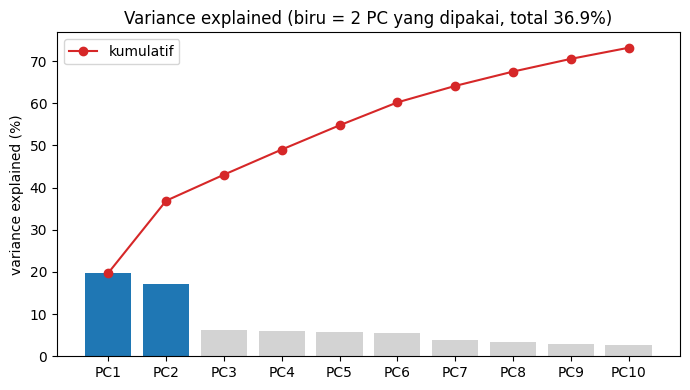

In [4]:
ev = pca_full.explained_variance_ratio_
k = len(ev)
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["tab:blue" if i < CFG["N_COMPONENTS"] else "lightgray" for i in range(k)]
ax.bar(range(1, k + 1), 100 * ev, color=colors)
ax.plot(range(1, k + 1), 100 * np.cumsum(ev), "o-", color="tab:red", label="kumulatif")
ax.set_xticks(range(1, k + 1)); ax.set_xticklabels([f"PC{i}" for i in range(1, k + 1)])
ax.set_ylabel("variance explained (%)")
ax.set_title(f"Variance explained (biru = 2 PC yang dipakai, total {100*ev[:2].sum():.1f}%)")
ax.legend(); plt.tight_layout(); savefig(fig, "01_variance_explained.png"); plt.show()

## 5. Grafik 2: deret waktu PC1 dan PC2

Satu contoh case per service (jenis fault yang sama, repetisi terkecil). Sumbu-x dalam menit relatif terhadap
`inject_time` (garis putus-putus merah). Kalau PC menangkap dampak fault, perubahan perilaku terlihat setelah garis itu.

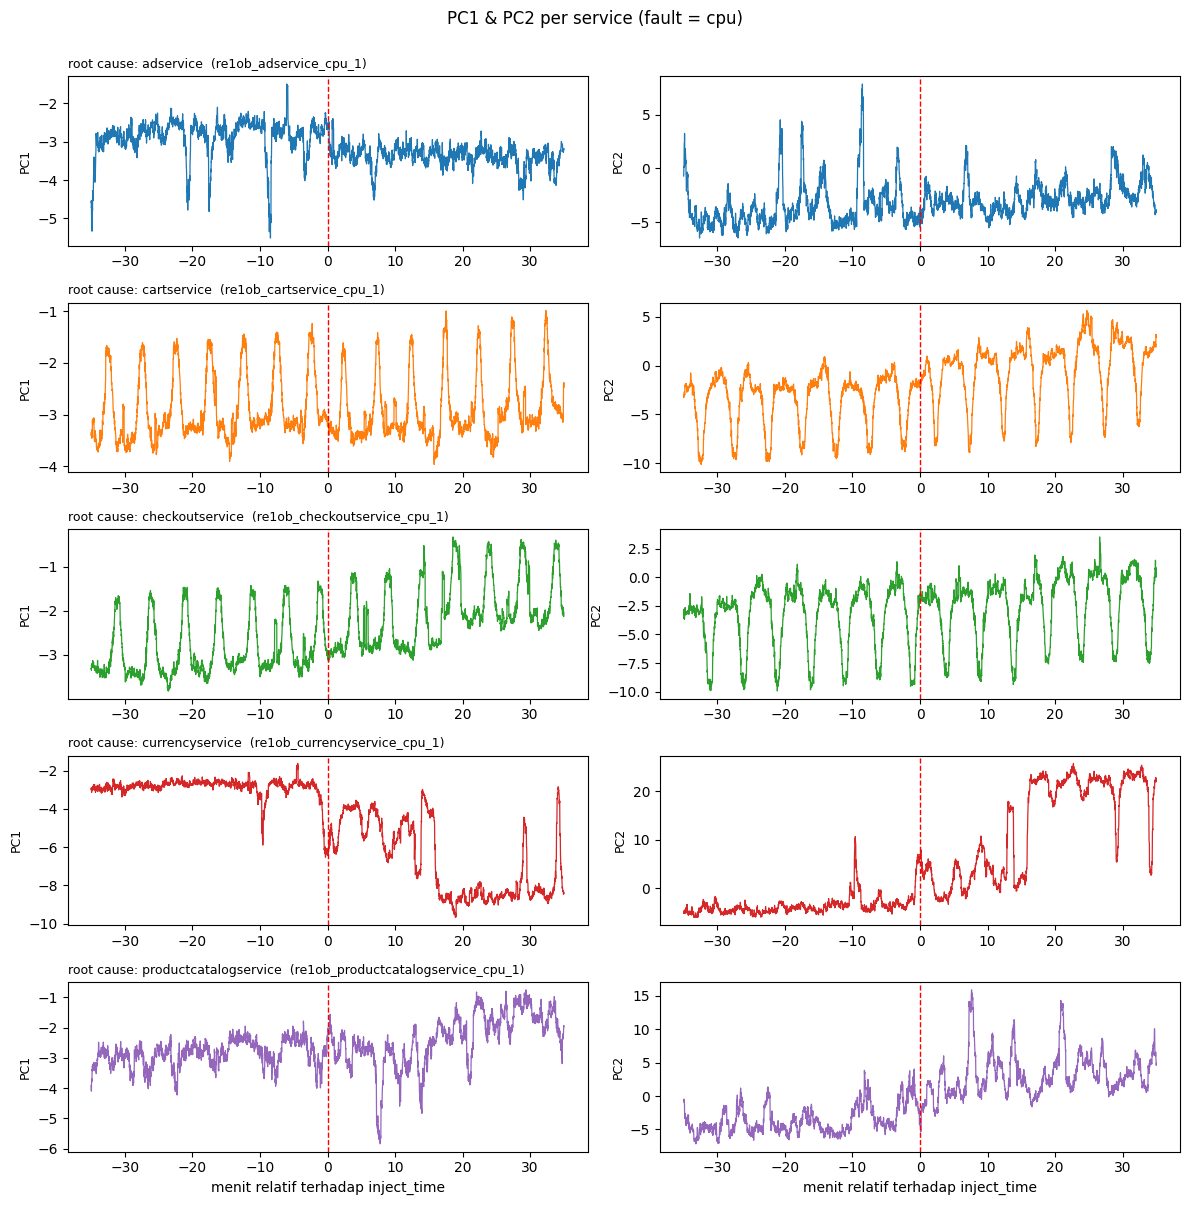

In [5]:
ex_fault = CFG["EXAMPLE_FAULT"] if CFG["EXAMPLE_FAULT"] in faults else faults[0]
ex = []
for s in classes:
    cand = [i for i in range(n) if DATA["y"][i] == s and DATA["fault"][i] == ex_fault]
    if cand:
        ex.append(min(cand, key=lambda i: DATA["rep"][i]))

fig, axes = plt.subplots(len(ex), 2, figsize=(12, 2.2 * len(ex) + 1), sharex=False, squeeze=False)
for r, i in enumerate(ex):
    t = (np.arange(len(P[i])) - DATA["inj"][i]) / 60.0
    for c in range(2):
        a = axes[r, c]
        a.plot(t, P[i][:, c], color=COLOR[DATA["y"][i]], lw=0.9)
        a.axvline(0, color="red", ls="--", lw=1)
        a.set_ylabel(f"PC{c+1}", fontsize=9)
        if c == 0:
            a.set_title(f"root cause: {DATA['y'][i]}  ({DATA['idx'].case.iloc[i]})", fontsize=9, loc="left")
    if r == len(ex) - 1:
        for c in range(2):
            axes[r, c].set_xlabel("menit relatif terhadap inject_time")
fig.suptitle(f"PC1 & PC2 per service (fault = {ex_fault})", y=1.0)
plt.tight_layout(); savefig(fig, "02_pc_timeseries.png"); plt.show()

## 6. Grafik 3: scatter titik waktu di ruang PC1-PC2

Kiri: titik **normal** (abu-abu) vs **faulty** (merah). Kanan: hanya titik faulty, diwarnai per `root_cause_service`.
Dipakai sampel acak titik per case supaya grafik tetap terbaca.

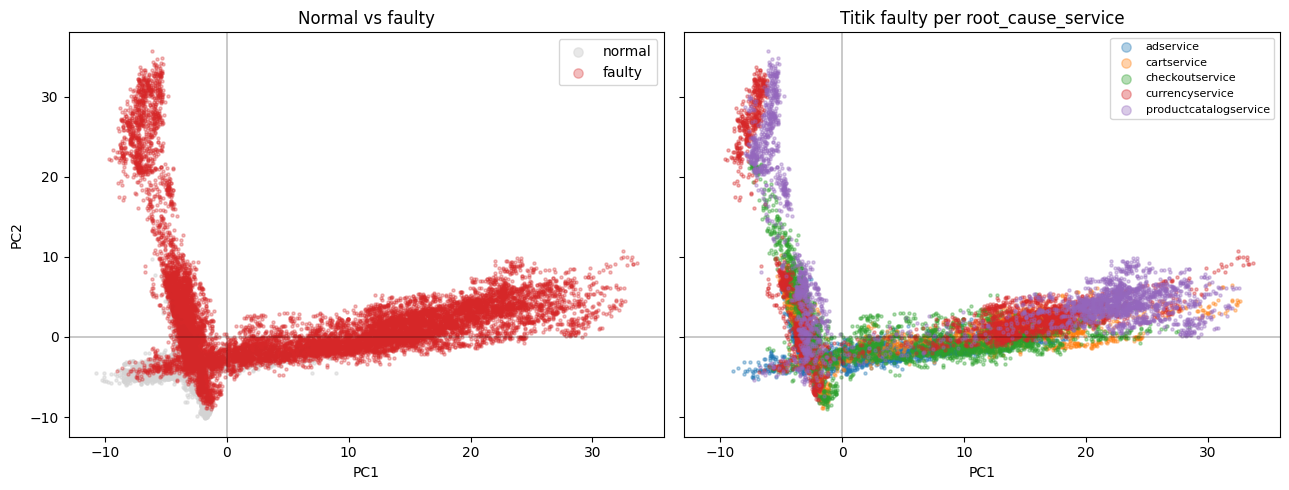

In [6]:
rng = np.random.default_rng(1)
Pn, Pf, Yf = [], [], []
for i in range(n):
    inj = DATA["inj"][i]
    a, b = P[i][:inj], P[i][inj:]
    Pn.append(a[rng.choice(len(a), min(120, len(a)), replace=False)])
    sel = rng.choice(len(b), min(120, len(b)), replace=False)
    Pf.append(b[sel]); Yf.extend([DATA["y"][i]] * len(sel))
Pn, Pf, Yf = np.concatenate(Pn), np.concatenate(Pf), np.array(Yf)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
ax[0].scatter(Pn[:, 0], Pn[:, 1], s=5, c="lightgray", alpha=0.5, label="normal")
ax[0].scatter(Pf[:, 0], Pf[:, 1], s=5, c="tab:red", alpha=0.3, label="faulty")
ax[0].set_title("Normal vs faulty"); ax[0].legend(markerscale=3)
for s in classes:
    m = Yf == s
    ax[1].scatter(Pf[m, 0], Pf[m, 1], s=5, color=COLOR[s], alpha=0.35, label=s)
ax[1].set_title("Titik faulty per root_cause_service"); ax[1].legend(markerscale=3, fontsize=8)
for a in ax:
    a.set_xlabel("PC1"); a.axhline(0, c="k", lw=0.3); a.axvline(0, c="k", lw=0.3)
ax[0].set_ylabel("PC2")
plt.tight_layout(); savefig(fig, "03_scatter_timepoints.png"); plt.show()

## 7. Grafik 4: scatter level case

Satu titik = satu case: rata-rata (PC1, PC2) periode faulty **dikurangi** periode normal.
Warna = `root_cause_service`, bentuk marker = jenis fault, tanda silang besar = centroid tiap service.
Skor silhouette (-1 s.d. 1) mengukur seberapa terpisah service di ruang 2-D ini; mendekati 0 berarti 2 PC saja
belum memisahkan service dengan baik.

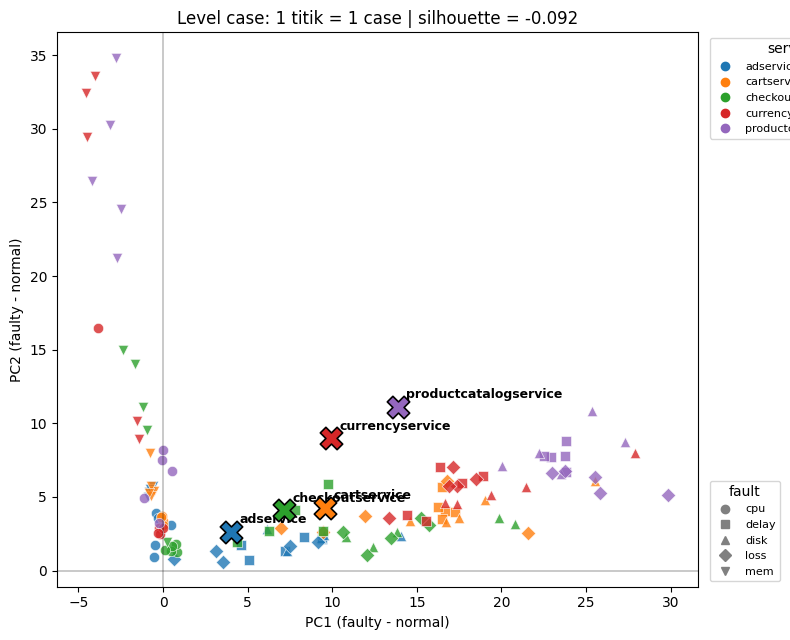

silhouette (service, ruang 2 PC) = -0.092


In [7]:
D = np.stack([P[i][DATA["inj"][i]:].mean(0) - P[i][:DATA["inj"][i]].mean(0) for i in range(n)])
y = DATA["y"]

fig, ax = plt.subplots(figsize=(8, 6.5))
for s in classes:
    for f in faults:
        m = (y == s) & (DATA["fault"] == f)
        if m.any():
            ax.scatter(D[m, 0], D[m, 1], color=COLOR[s], marker=MARK[f], s=55, alpha=0.8,
                       edgecolor="white", linewidth=0.5)
for s in classes:
    c = D[y == s].mean(0)
    ax.scatter(*c, color=COLOR[s], marker="X", s=260, edgecolor="black", linewidth=1.2, zorder=5)
    ax.annotate(s, c, xytext=(6, 6), textcoords="offset points", fontsize=9, weight="bold")
ax.axhline(0, c="k", lw=0.3); ax.axvline(0, c="k", lw=0.3)
ax.set_xlabel("PC1 (faulty - normal)"); ax.set_ylabel("PC2 (faulty - normal)")
sil = silhouette_score(D, y) if len(classes) > 1 else float("nan")
ax.set_title(f"Level case: 1 titik = 1 case | silhouette = {sil:.3f}")
h1 = [Line2D([], [], marker="o", ls="", color=COLOR[s], label=s) for s in classes]
h2 = [Line2D([], [], marker=MARK[f], ls="", color="gray", label=f) for f in faults]
leg1 = ax.legend(handles=h1, title="service", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.add_artist(leg1)
ax.legend(handles=h2, title="fault", loc="lower left", bbox_to_anchor=(1.01, 0), fontsize=8)
plt.tight_layout(); savefig(fig, "04_scatter_cases.png"); plt.show()
print(f"silhouette (service, ruang 2 PC) = {sil:.3f}")

## 8. Cara membaca hasil

- **Variance explained** kecil (mis. di bawah ~50%) berarti 2 PC hanya menangkap sebagian variasi. Pola yang tidak terlihat
  di grafik belum tentu tidak ada, mungkin hanya ada di PC berikutnya.
- **Deret waktu**: perubahan level atau osilasi PC setelah `inject_time` menandakan fault terdeteksi oleh PC tersebut.
  Itu belum berarti PC memisahkan *service* penyebabnya.
- **Scatter case**: kelompok warna yang terpisah = service cukup dibedakan oleh 2 PC. Warna bercampur tapi marker
  (jenis fault) mengelompok = 2 PC lebih mencerminkan jenis fault daripada service.
- PCA tidak memakai label dan bersifat linear; metrik per service yang berbeda-beda bisa saling menimpa di 2 dimensi.
  Untuk pemisahan service yang lebih baik, coba lebih banyak PC, PCA per kelompok service, atau representasi hasil SSL.
- Semua gambar tersimpan di folder `pca_outputs/`.